In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [106]:
df = pd.read_csv("../data/student_data.csv")

df.head()

,student_id,age,attendance_pct,study_hours_per_week,previous_score,assignment_completion_pct,internal_assessment_score,participation_score,sleep_hours_per_day,extracurricular_hours_per_week,failed_subjects,performance_category
0,STU21500,24,73.8,7.9,58.3,100.0,55.6,4.7,4.9,5.0,0,Low
1,STU16476,19,58.1,3.9,61.5,100.0,55.5,8.8,5.3,0.0,1,Low
2,STU23168,18,77.5,24.5,86.2,66.9,69.3,8.3,6.6,7.1,0,High
3,STU10863,17,76.1,17.1,78.8,75.7,62.5,8.4,8.0,7.0,1,High
4,STU15971,22,86.3,4.6,76.2,79.6,72.6,5.5,6.4,2.0,0,Low


In [107]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
student_id                        0
age                               0
attendance_pct                    0
study_hours_per_week              0
previous_score                    0
assignment_completion_pct         0
internal_assessment_score         0
participation_score               0
sleep_hours_per_day               0
extracurricular_hours_per_week    0
failed_subjects                   0
performance_category              0
dtype: int64

Duplicate Rows: 0


In [108]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (15000, 12)

Column Names:
['student_id', 'age', 'attendance_pct', 'study_hours_per_week', 'previous_score', 'assignment_completion_pct', 'internal_assessment_score', 'participation_score', 'sleep_hours_per_day', 'extracurricular_hours_per_week', 'failed_subjects', 'performance_category']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   student_id                      15000 non-null  str    
 1   age                             15000 non-null  int64  
 2   attendance_pct                  15000 non-null  float64
 3   study_hours_per_week            15000 non-null  float64
 4   previous_score                  15000 non-null  float64
 5   assignment_completion_pct       15000 non-null  float64
 6   internal_assessment_score       15000 non-null  float64
 7   participation_score  

In [109]:
# Input features
X = df.drop(columns=["student_id", "performance_category"])

# Target variable
y = df["performance_category"]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:
['age', 'attendance_pct', 'study_hours_per_week', 'previous_score', 'assignment_completion_pct', 'internal_assessment_score', 'participation_score', 'sleep_hours_per_day', 'extracurricular_hours_per_week', 'failed_subjects']

Target Variable:
performance_category

Features Shape: (15000, 10)
Target Shape: (15000,)


In [110]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Performance Classes:")
for i, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} → {i}")

Performance Classes:
High → 0
Low → 1
Medium → 2


In [111]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (12000, 10)
Testing Data Shape: (3000, 10)


In [112]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [113]:
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train_scaled: (12000, 10)
X_test_scaled: (3000, 10)
y_train: (12000,)
y_test: (3000,)


In [114]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [115]:
y_pred_baseline = baseline_model.predict(X_test_scaled)

In [116]:
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_precision = precision_score(
    y_test, y_pred_baseline, average="weighted"
)
baseline_recall = recall_score(
    y_test, y_pred_baseline, average="weighted"
)
baseline_f1 = f1_score(
    y_test, y_pred_baseline, average="weighted"
)

print("Baseline Model Results")
print("-" * 30)
print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-Score:  {baseline_f1:.4f}")

Baseline Model Results
------------------------------
Accuracy:  0.6920
Precision: 0.6958
Recall:    0.6920
F1-Score:  0.6933


In [117]:
print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

        High       0.76      0.78      0.77       990
         Low       0.77      0.71      0.74       990
      Medium       0.56      0.59      0.57      1020

    accuracy                           0.69      3000
   macro avg       0.70      0.69      0.69      3000
weighted avg       0.70      0.69      0.69      3000



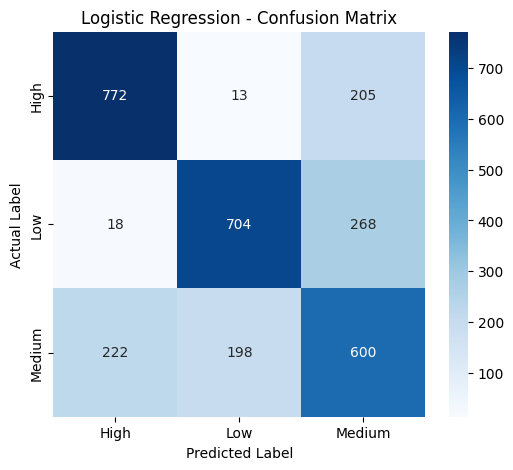

In [118]:
cm_baseline = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_baseline,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [119]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [120]:
# Number of input features
input_features = X_train_scaled.shape[1]

# Number of output classes
num_classes = len(label_encoder.classes_)

# Create ANN model
ann_model = Sequential([
    Dense(32, activation="relu", input_shape=(input_features,)),
    Dense(16, activation="relu"),
    Dense(num_classes, activation="softmax")
])

# Display model architecture
ann_model.summary()

c:\Users\palhi\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 931 (3.64 KB)

 Trainable params: 931 (3.64 KB)

 Non-trainable params: 0 (0.00 B)

In [121]:
ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


In [122]:
history = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5904 - loss: 0.8382 - val_accuracy: 0.6604 - val_loss: 0.7061
Epoch 2/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6855 - loss: 0.6744 - val_accuracy: 0.6725 - val_loss: 0.6858
Epoch 3/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6897 - loss: 0.6608 - val_accuracy: 0.6808 - val_loss: 0.6823
Epoch 4/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6920 - loss: 0.6548 - val_accuracy: 0.6804 - val_loss: 0.6826
Epoch 5/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6953 - loss: 0.6506 - val_accuracy: 0.6829 - val_loss: 0.6826
Epoch 6/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6960 - loss: 0.6479 - val_accuracy: 0.6833 - val_loss: 0.6816
Epoch 7/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6961 - loss: 0.6461 - val_accuracy: 0.6762 - val_loss: 0.6848
Epoch 8/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6975 - loss: 0.6447 - val_accuracy: 0.

In [123]:
test_loss, test_accuracy = ann_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.6939
Test Accuracy: 0.6717


In [124]:
y_pred_prob = ann_model.predict(X_test_scaled)

# Convert probabilities into predicted class labels
y_pred_ann = y_pred_prob.argmax(axis=1)

print("Predictions completed!")

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Predictions completed!


In [125]:
ann_accuracy = accuracy_score(y_test, y_pred_ann)

ann_precision = precision_score(
    y_test,
    y_pred_ann,
    average="weighted"
)

ann_recall = recall_score(
    y_test,
    y_pred_ann,
    average="weighted"
)

ann_f1 = f1_score(
    y_test,
    y_pred_ann,
    average="weighted"
)

print("ANN Model Results")
print("-" * 30)
print(f"Accuracy:  {ann_accuracy:.4f}")
print(f"Precision: {ann_precision:.4f}")
print(f"Recall:    {ann_recall:.4f}")
print(f"F1-Score:  {ann_f1:.4f}")

ANN Model Results
------------------------------
Accuracy:  0.6717
Precision: 0.6817
Recall:    0.6717
F1-Score:  0.6752


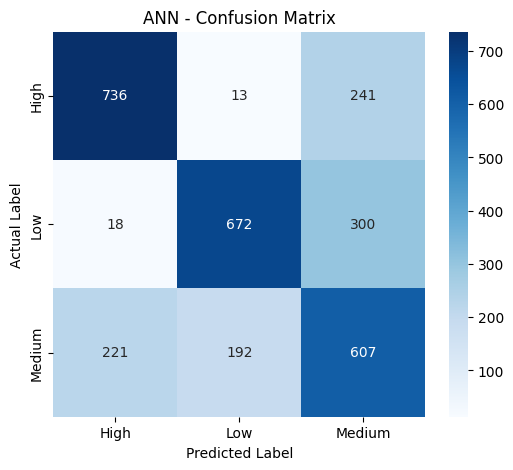

In [126]:
cm_ann = confusion_matrix(y_test, y_pred_ann)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_ann,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ANN - Confusion Matrix")

plt.show()

In [127]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "ANN"],
    "Accuracy": [baseline_accuracy, ann_accuracy],
    "Precision": [baseline_precision, ann_precision],
    "Recall": [baseline_recall, ann_recall],
    "F1-Score": [baseline_f1, ann_f1]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.692000,0.695762,0.692000,0.693347
1,ANN,0.671667,0.681743,0.671667,0.675151


In [128]:
import joblib

joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(label_encoder, "../models/label_encoder.pkl")

print("Scaler and Label Encoder saved successfully!")

Scaler and Label Encoder saved successfully!


In [129]:
import os

print("Saved model files:")
print(os.listdir("../models"))

Saved model files:
['label_encoder.pkl', 'scaler.pkl', 'student_performance.keras']


In [130]:
comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.6920,0.6958,0.6920,0.6933
1,ANN,0.6717,0.6817,0.6717,0.6752


In [131]:
ann_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,795 (10.92 KB)

 Trainable params: 931 (3.64 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,864 (7.29 KB)

In [132]:
ann_model.save("../models/student_performance.keras")

print("ANN model saved successfully!")

ANN model saved successfully!
